# 02 - Exploratory Data Analysis (EDA): Indian Power Grid (Jan–Aug 2026)

**Author:** EDA Lead (Member 2)

**Objective:** Perform a rigorous, multi-level exploration of the cleaned energy datasets to:
1. Validate data quality post-cleaning (Member 1 handoff audit).
2. Identify national-level trends, seasonal shifts, and regional disparities.
3. Profile state-level vulnerabilities using statistical measures.
4. Surface features and insights for **Member 3** (Feature Engineering & ML) and **Member 4** (Dashboard).

---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 12

## 1. Data Loading (Member 1 Handoff)
We strictly load the **cleaned, validated CSVs** from `data/processed/`. 
We never touch the raw `.xlsx` in EDA — that is Member 1's domain.

In [2]:
DATA_DIR = 'data/processed/'

df_state = pd.read_csv(f'{DATA_DIR}fact_power_state_level.csv', parse_dates=['month_start'])
df_region = pd.read_csv(f'{DATA_DIR}fact_power_regional_level.csv', parse_dates=['month_start'])
df_all_india = pd.read_csv(f'{DATA_DIR}fact_power_all_india.csv', parse_dates=['month_start'])

print(f'State-level  : {df_state.shape[0]} rows × {df_state.shape[1]} cols | {df_state["entity_name"].nunique()} entities')
print(f'Regional     : {df_region.shape[0]} rows × {df_region.shape[1]} cols | {df_region["entity_name"].nunique()} entities')
print(f'All-India    : {df_all_india.shape[0]} rows × {df_all_india.shape[1]} cols')

State-level  : 288 rows × 27 cols | 36 entities
Regional     : 40 rows × 27 cols | 5 entities
All-India    : 8 rows × 27 cols


## 2. Post-Cleaning Data Quality Audit
Before any analysis, we verify that the cleaning pipeline delivered zero nulls and no negative metrics. Skipping this step is a common EDA mistake — you must never trust upstream data blindly.

In [3]:
# Check nulls across all three datasets
for name, df in [('State', df_state), ('Region', df_region), ('All-India', df_all_india)]:
    null_count = df.isnull().sum().sum()
    print(f'{name}: {null_count} null values')

# Check for negative values in metric columns
metric_cols = ['energy_requirement_mu', 'energy_supplied_mu', 'energy_not_supplied_mu',
               'peak_demand_mw', 'peak_met_mw', 'demand_not_met_mw']
for name, df in [('State', df_state), ('Region', df_region), ('All-India', df_all_india)]:
    neg_counts = {col: (df[col] < 0).sum() for col in metric_cols if col in df.columns}
    if any(v > 0 for v in neg_counts.values()):
        print(f'⚠️ {name} has negative values: {neg_counts}')
    else:
        print(f'✅ {name}: No negative metric values')

print('\n--- State-Level Descriptive Statistics ---')
df_state[metric_cols + ['load_factor_pct']].describe().round(2)

State: 0 null values
Region: 0 null values
All-India: 0 null values
✅ State: No negative metric values
✅ Region: No negative metric values
✅ All-India: No negative metric values

--- State-Level Descriptive Statistics ---


,energy_requirement_mu,energy_supplied_mu,energy_not_supplied_mu,peak_demand_mw,peak_met_mw,demand_not_met_mw,load_factor_pct
count,288.00,288.00,288.00,288.00,288.00,288.00,288.00
mean,4269.28,4264.95,4.32,7751.55,7730.33,21.22,73.09
std,4965.63,4961.62,13.44,8877.06,8856.91,88.14,8.89
min,6.00,6.00,0.00,13.00,13.00,0.00,51.70
25%,185.25,185.25,0.00,371.75,371.75,0.00,67.79
50%,1947.50,1944.50,0.00,3321.00,3320.00,0.00,73.27
75%,7739.00,7715.00,2.00,13847.25,13847.25,2.00,79.73
max,20235.00,20102.00,133.00,33197.00,32673.00,655.00,92.56


## 3. All-India National Trends (RQ1)
**Research Question:** How does the national energy requirement and peak demand shift across the year?

We plot two dual-line charts: one for Energy (MU) and one for Peak Power (MW), each comparing demand vs. supply.

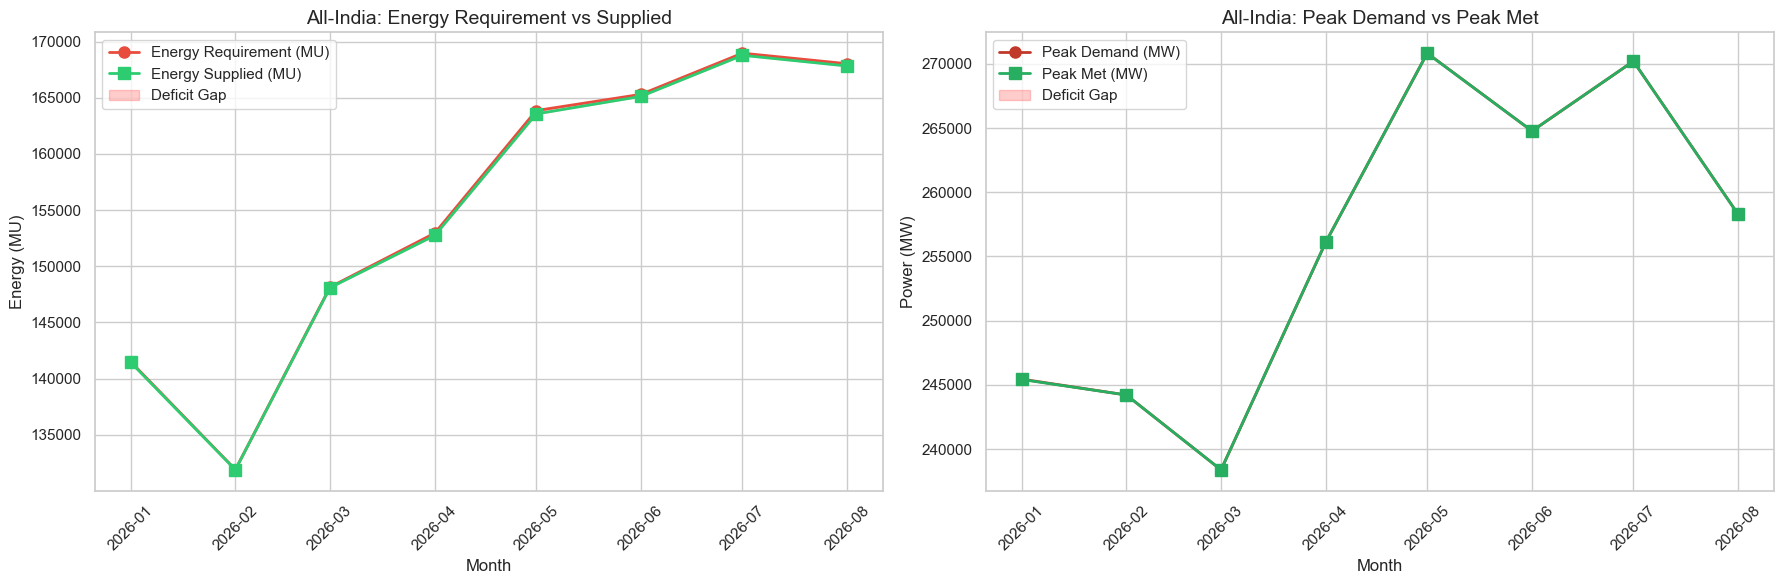

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Energy Requirement vs Supplied
axes[0].plot(df_all_india['month_start'], df_all_india['energy_requirement_mu'], 'o-', color='#e74c3c', linewidth=2, markersize=8, label='Energy Requirement (MU)')
axes[0].plot(df_all_india['month_start'], df_all_india['energy_supplied_mu'], 's-', color='#2ecc71', linewidth=2, markersize=8, label='Energy Supplied (MU)')
axes[0].fill_between(df_all_india['month_start'], df_all_india['energy_supplied_mu'], df_all_india['energy_requirement_mu'], alpha=0.2, color='red', label='Deficit Gap')
axes[0].set_title('All-India: Energy Requirement vs Supplied', fontsize=14)
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Energy (MU)')
axes[0].legend()
axes[0].tick_params(axis='x', rotation=45)

# Peak Demand vs Peak Met
axes[1].plot(df_all_india['month_start'], df_all_india['peak_demand_mw'], 'o-', color='#c0392b', linewidth=2, markersize=8, label='Peak Demand (MW)')
axes[1].plot(df_all_india['month_start'], df_all_india['peak_met_mw'], 's-', color='#27ae60', linewidth=2, markersize=8, label='Peak Met (MW)')
axes[1].fill_between(df_all_india['month_start'], df_all_india['peak_met_mw'], df_all_india['peak_demand_mw'], alpha=0.2, color='red', label='Deficit Gap')
axes[1].set_title('All-India: Peak Demand vs Peak Met', fontsize=14)
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Power (MW)')
axes[1].legend()
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

> **Finding (RQ1):** The shaded deficit gap is small but persistent. Both energy and peak demand grow month-over-month as cumulative values compound. The critical question for ML (Member 3) is whether the *rate* of deficit growth is accelerating.

## 4. Energy Deficit & Peak Deficit Over Time
Plotting the deficit itself (not demand vs. supply) to see if grid stress is worsening.

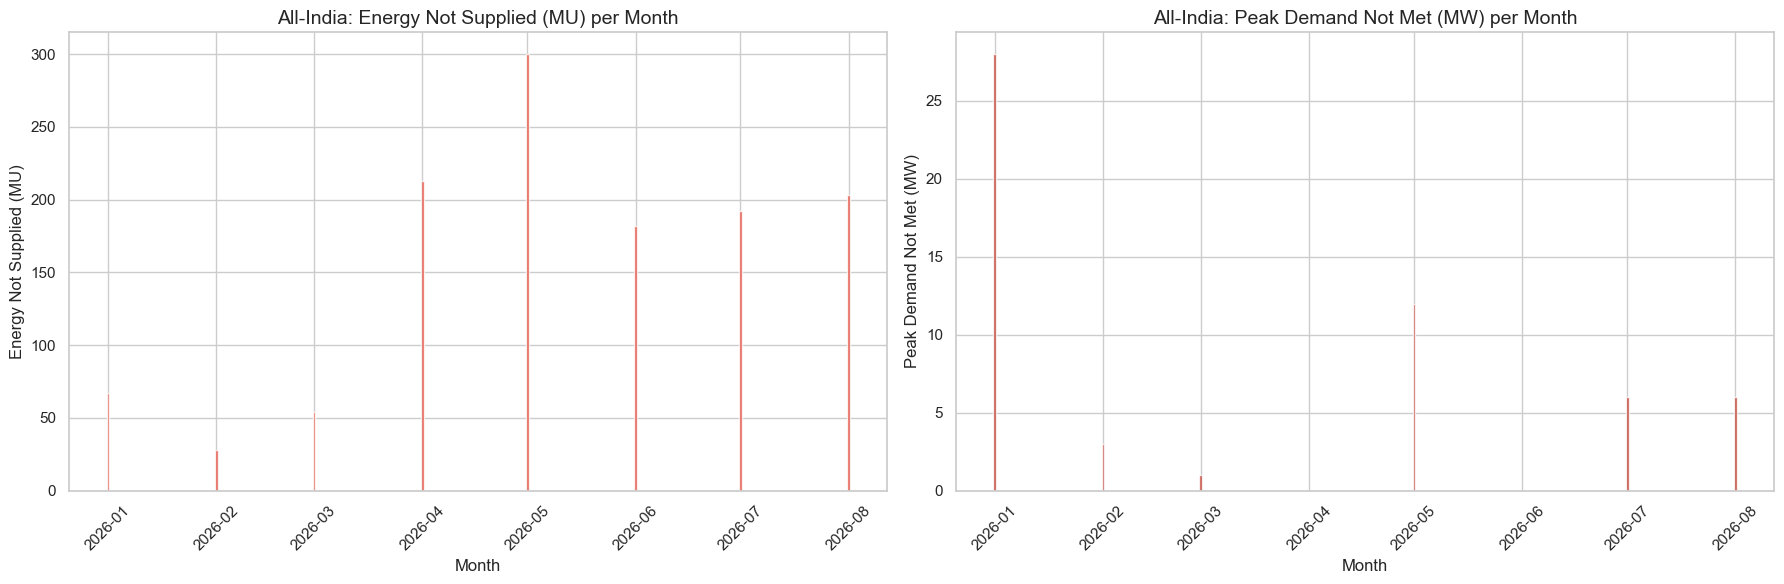

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

axes[0].bar(df_all_india['month_start'], df_all_india['energy_not_supplied_mu'], color='#e74c3c', alpha=0.8)
axes[0].set_title('All-India: Energy Not Supplied (MU) per Month', fontsize=14)
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Energy Not Supplied (MU)')
axes[0].tick_params(axis='x', rotation=45)

axes[1].bar(df_all_india['month_start'], df_all_india['demand_not_met_mw'], color='#c0392b', alpha=0.8)
axes[1].set_title('All-India: Peak Demand Not Met (MW) per Month', fontsize=14)
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Peak Demand Not Met (MW)')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## 5. Regional Grid Stress Comparison (RQ2)
**Research Question:** Which macro-regions carry the most grid stress?

We compare both **maximum peak deficit** and **average energy deficit %** across regions.

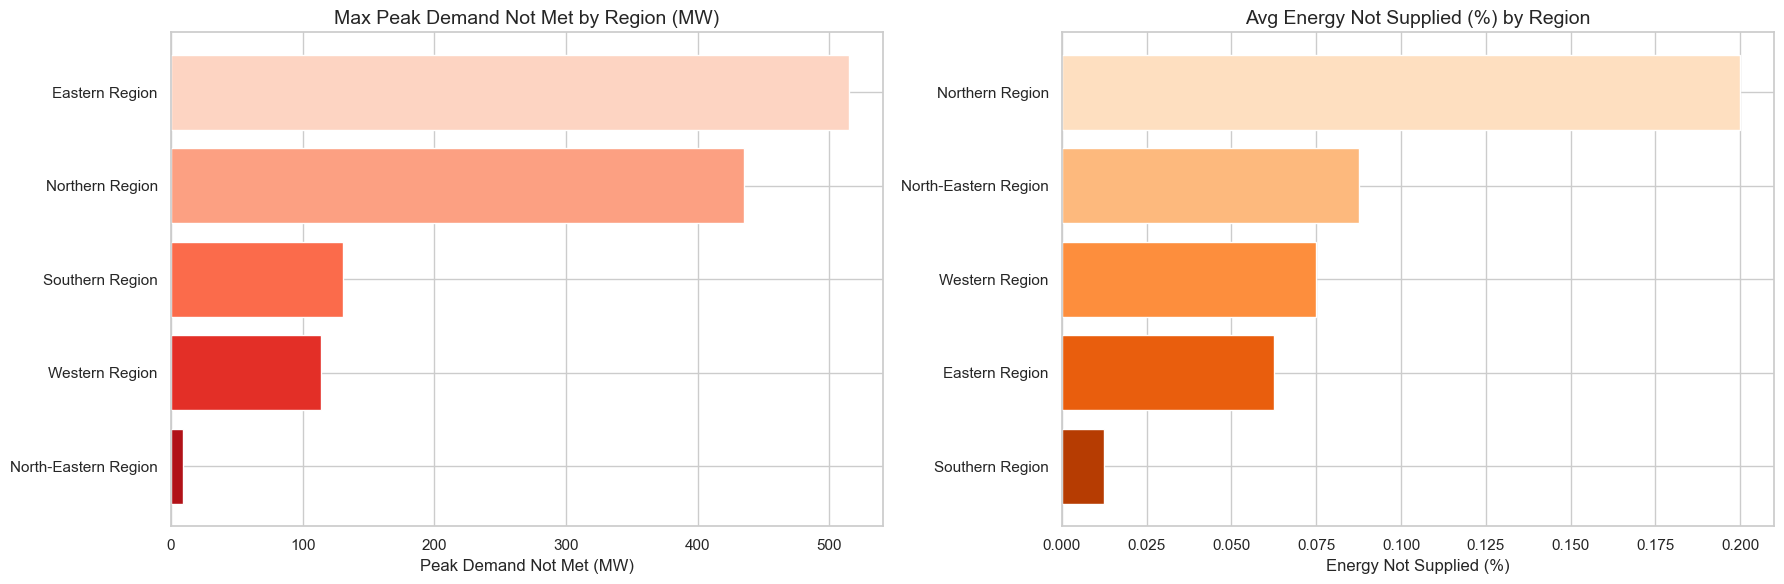

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Maximum Peak Demand Not Met
region_peak_deficit = df_region.groupby('entity_name')['demand_not_met_mw'].max().sort_values(ascending=True).reset_index()
axes[0].barh(region_peak_deficit['entity_name'], region_peak_deficit['demand_not_met_mw'], color=sns.color_palette('Reds_r', len(region_peak_deficit)))
axes[0].set_title('Max Peak Demand Not Met by Region (MW)', fontsize=14)
axes[0].set_xlabel('Peak Demand Not Met (MW)')

# Average Energy Not Supplied %
region_energy_deficit_pct = df_region.groupby('entity_name')['energy_ns_pct'].mean().sort_values(ascending=True).reset_index()
axes[1].barh(region_energy_deficit_pct['entity_name'], region_energy_deficit_pct['energy_ns_pct'], color=sns.color_palette('Oranges_r', len(region_energy_deficit_pct)))
axes[1].set_title('Avg Energy Not Supplied (%) by Region', fontsize=14)
axes[1].set_xlabel('Energy Not Supplied (%)')

plt.tight_layout()
plt.show()

> **Finding (RQ2):** The Northern and Western regions dominate in absolute deficit. However, when looking at the *percentage* of energy not supplied, smaller regions may show higher proportional stress. **Member 4** should display both absolute and relative metrics on the dashboard.

## 6. Seasonal Demand Heatmap (Region × Month)
A heatmap reveals which regions experience seasonal peaks and when. This is essential for **Member 3** to decide if `month` is a useful feature.

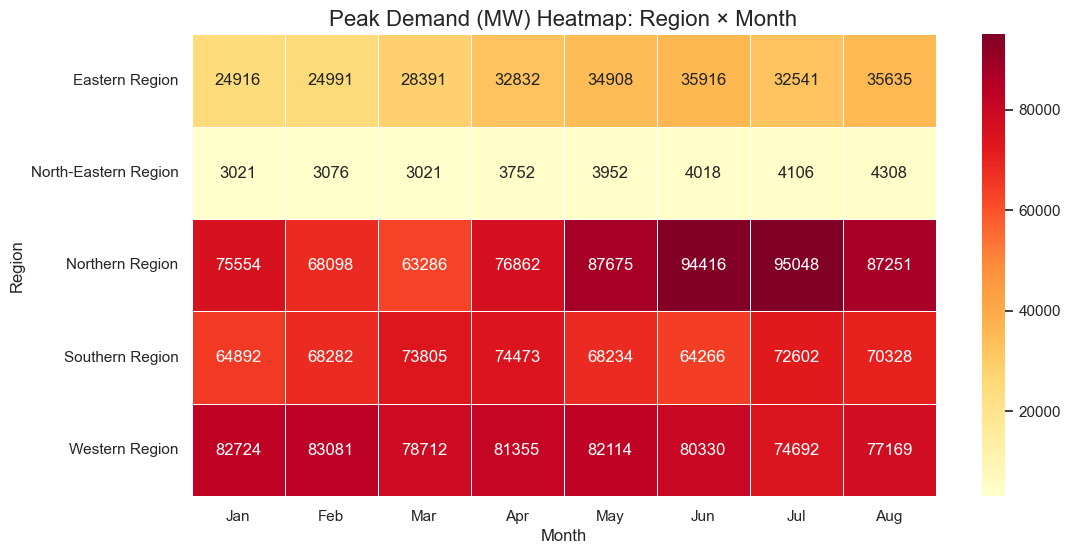

In [7]:
# Pivot: Region × Month → Peak Demand
heatmap_data = df_region.pivot_table(index='entity_name', columns='month', values='peak_demand_mw', aggfunc='max')
month_labels = {1:'Jan', 2:'Feb', 3:'Mar', 4:'Apr', 5:'May', 6:'Jun', 7:'Jul', 8:'Aug'}
heatmap_data.columns = [month_labels.get(m, m) for m in heatmap_data.columns]

plt.figure(figsize=(12, 6))
sns.heatmap(heatmap_data, annot=True, fmt='.0f', cmap='YlOrRd', linewidths=0.5)
plt.title('Peak Demand (MW) Heatmap: Region × Month', fontsize=16)
plt.ylabel('Region')
plt.xlabel('Month')
plt.show()

> **Finding:** Summer months (Apr–Jul) consistently show higher peak demand across all regions. `month` and `fy_month_index` are **confirmed useful features** for Member 3.

## 7. Correlation Analysis (Feature Selection for ML)
The correlation matrix on numeric state-level columns guides **Member 3** on which features are redundant and which are independent.

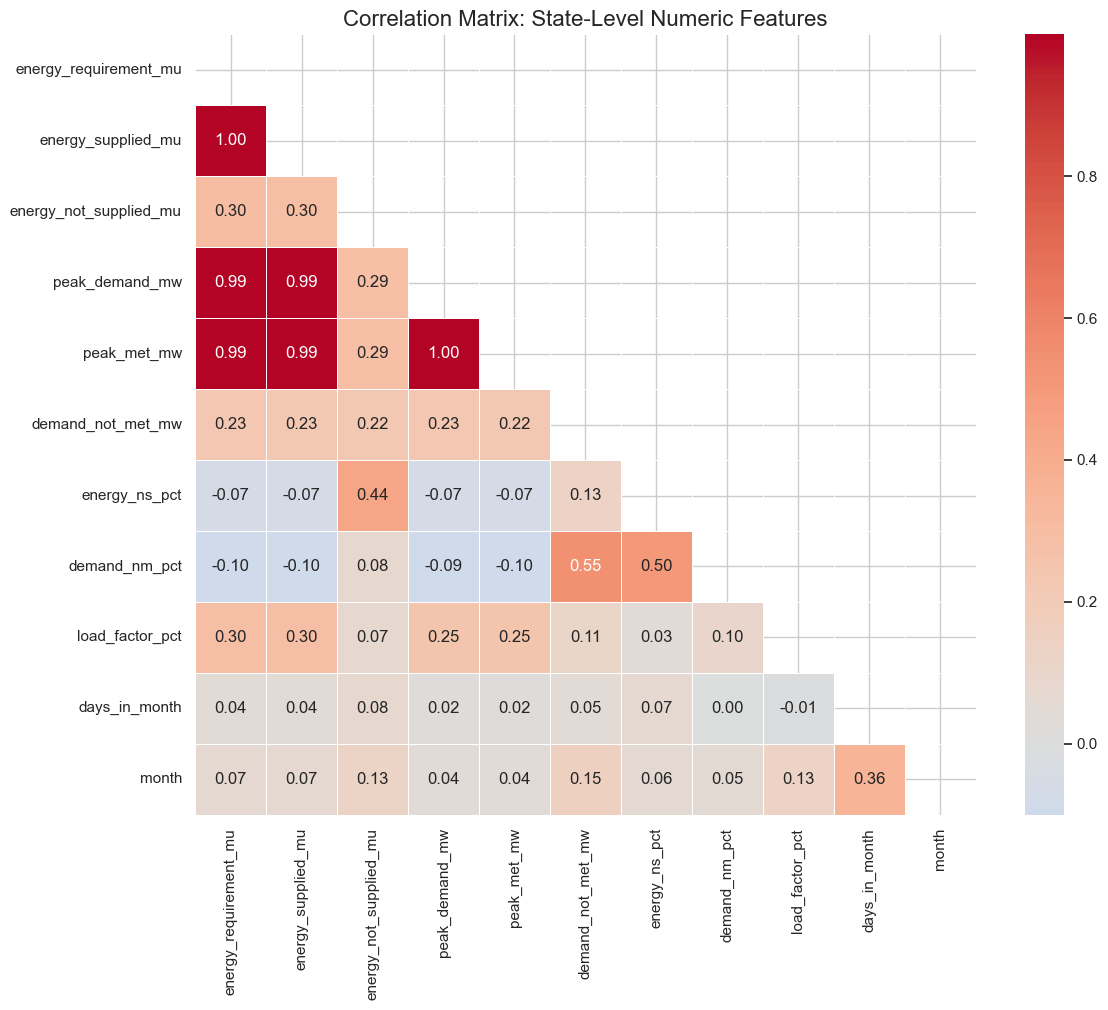

In [8]:
corr_cols = ['energy_requirement_mu', 'energy_supplied_mu', 'energy_not_supplied_mu',
             'peak_demand_mw', 'peak_met_mw', 'demand_not_met_mw',
             'energy_ns_pct', 'demand_nm_pct', 'load_factor_pct', 'days_in_month', 'month']

corr_matrix = df_state[corr_cols].corr()

plt.figure(figsize=(12, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=0.5)
plt.title('Correlation Matrix: State-Level Numeric Features', fontsize=16)
plt.tight_layout()
plt.show()

> **Finding for Member 3:**
> - `energy_requirement_mu` and `peak_demand_mw` are highly correlated — pick one for volume-based models.
> - `load_factor_pct` is weakly correlated with deficit metrics — it provides **independent information** and should be retained.
> - `energy_ns_pct` and `demand_nm_pct` are the best normalized deficit features.

## 8. Load Factor Distribution (Grid Efficiency)
Load Factor tells us how efficiently the grid is utilized relative to its peak capacity. Low load factor = bursty demand, high load factor = steady base-load.

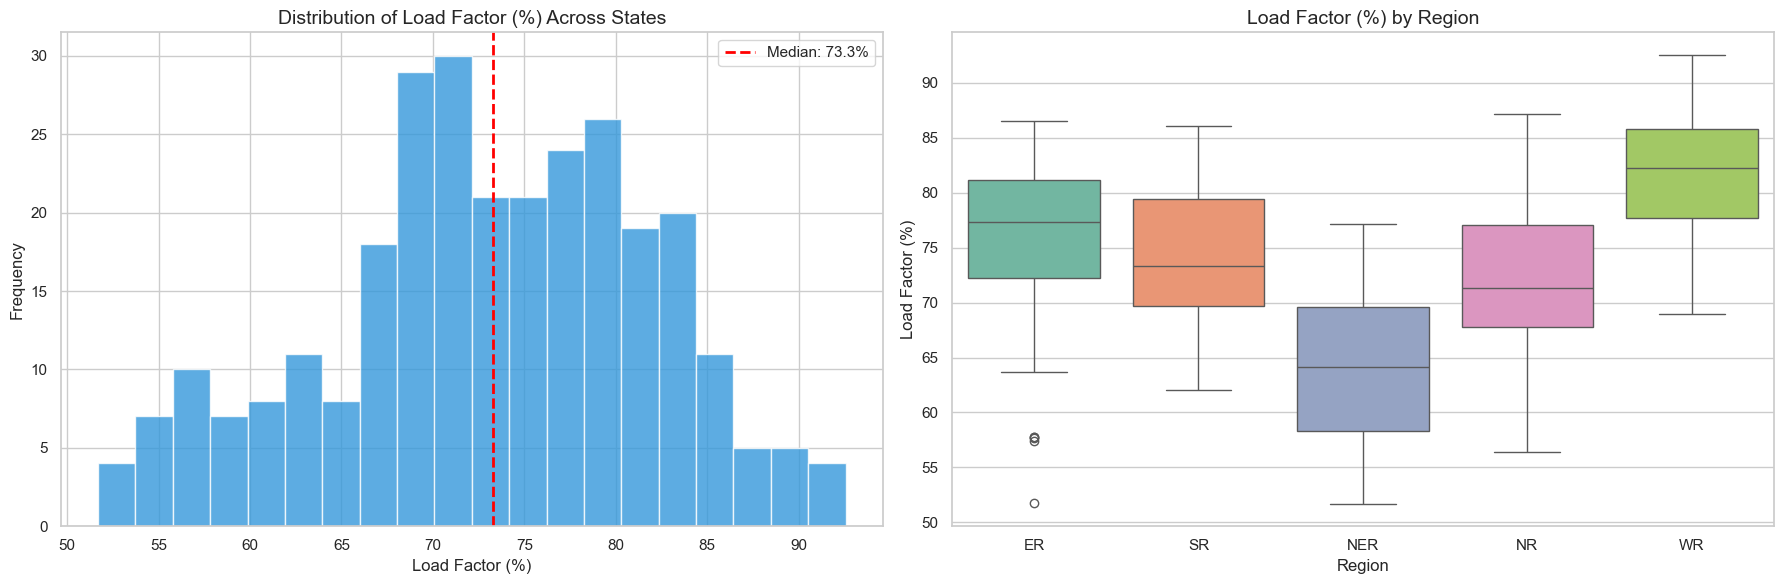

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Histogram of Load Factor
axes[0].hist(df_state['load_factor_pct'], bins=20, color='#3498db', edgecolor='white', alpha=0.8)
axes[0].axvline(df_state['load_factor_pct'].median(), color='red', linestyle='--', linewidth=2, label=f'Median: {df_state["load_factor_pct"].median():.1f}%')
axes[0].set_title('Distribution of Load Factor (%) Across States', fontsize=14)
axes[0].set_xlabel('Load Factor (%)')
axes[0].set_ylabel('Frequency')
axes[0].legend()

# Boxplot of Load Factor by Region
sns.boxplot(data=df_state, x='region_code', y='load_factor_pct', palette='Set2', ax=axes[1])
axes[1].set_title('Load Factor (%) by Region', fontsize=14)
axes[1].set_xlabel('Region')
axes[1].set_ylabel('Load Factor (%)')

plt.tight_layout()
plt.show()

> **Finding:** Most states cluster around 68–80% load factor. NER (North-Eastern Region) shows the widest spread, indicating highly variable grid utilization. This is a strong signal for **Member 3's** clustering model.

## 9. State-Level Vulnerability Profiling (RQ3)
**Research Question:** Which states are most vulnerable to power deficits?

We derive a `deficit_severity_ratio` and compare it against `load_factor_pct` to create a 2D vulnerability profile.

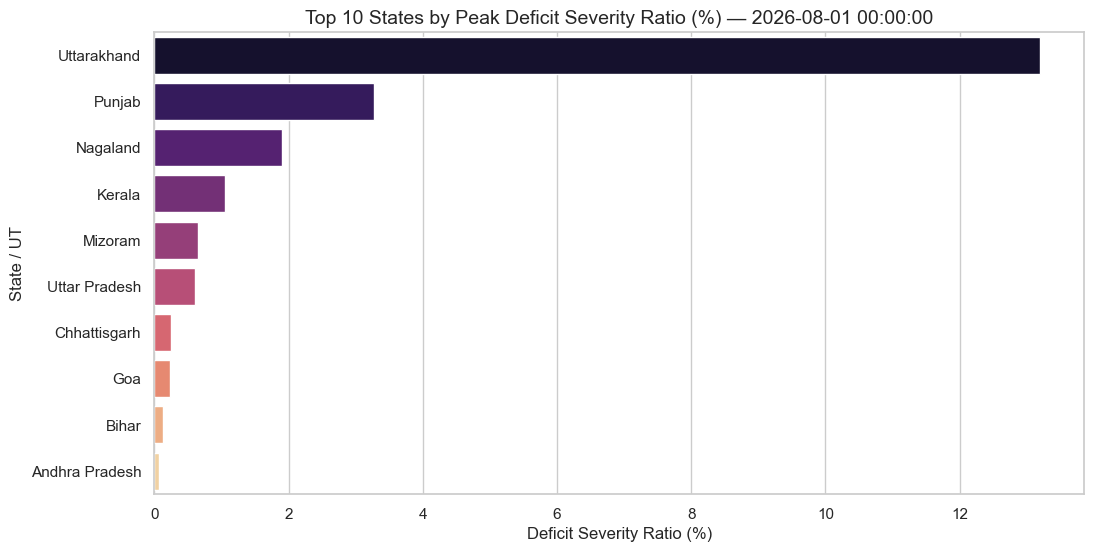

In [10]:
# Use latest month for cross-sectional snapshot
latest_month = df_state['month_start'].max()
df_snap = df_state[df_state['month_start'] == latest_month].copy()

# Deficit Severity Ratio (%)
df_snap['deficit_severity_ratio'] = np.where(
    df_snap['peak_demand_mw'] > 0,
    (df_snap['demand_not_met_mw'] / df_snap['peak_demand_mw']) * 100,
    0
)

# Top 10 deficit states
top10 = df_snap.sort_values('deficit_severity_ratio', ascending=False).head(10)
plt.figure(figsize=(12, 6))
sns.barplot(data=top10, x='deficit_severity_ratio', y='entity_name', palette='magma')
plt.title(f'Top 10 States by Peak Deficit Severity Ratio (%) — {latest_month}', fontsize=14)
plt.xlabel('Deficit Severity Ratio (%)')
plt.ylabel('State / UT')
plt.show()

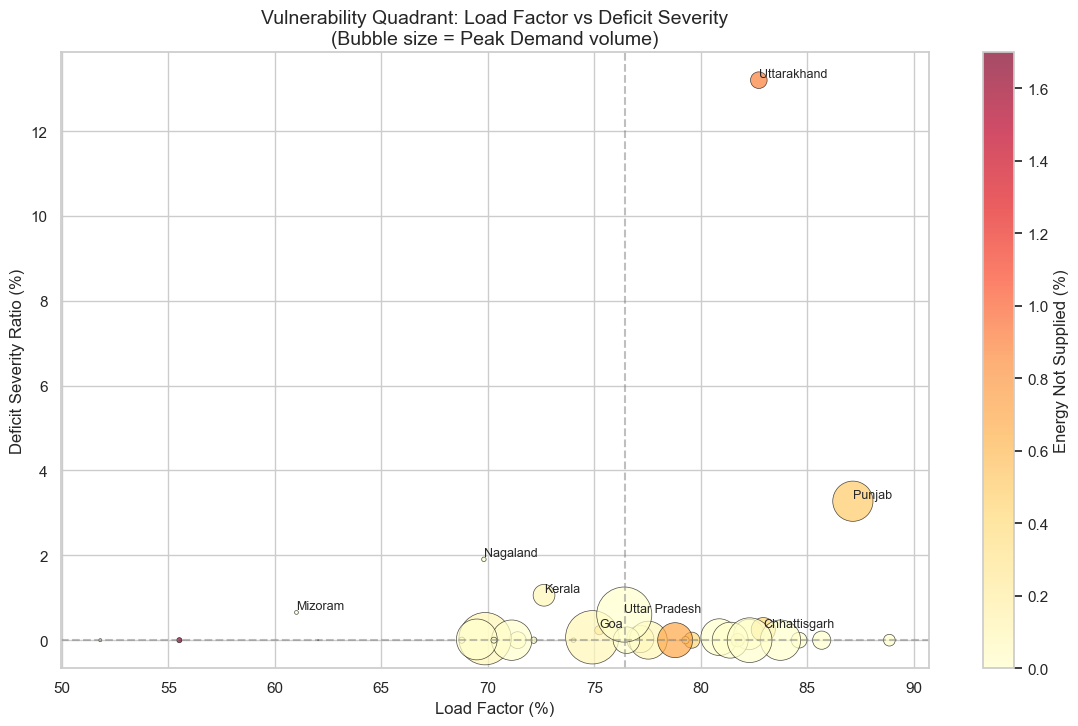

In [11]:
# 2D Scatter: Load Factor vs Deficit Severity (Vulnerability Quadrant)
plt.figure(figsize=(14, 8))
scatter = plt.scatter(
    df_snap['load_factor_pct'],
    df_snap['deficit_severity_ratio'],
    s=df_snap['peak_demand_mw'] / 20,  # bubble size = demand volume
    c=df_snap['energy_ns_pct'],
    cmap='YlOrRd',
    alpha=0.7,
    edgecolors='black',
    linewidth=0.5
)
plt.colorbar(scatter, label='Energy Not Supplied (%)')

# Annotate top states
for _, row in df_snap.nlargest(8, 'deficit_severity_ratio').iterrows():
    plt.annotate(row['entity_name'], (row['load_factor_pct'], row['deficit_severity_ratio']),
                 fontsize=9, ha='left', va='bottom')

plt.axhline(df_snap['deficit_severity_ratio'].median(), color='gray', linestyle='--', alpha=0.5)
plt.axvline(df_snap['load_factor_pct'].median(), color='gray', linestyle='--', alpha=0.5)
plt.title('Vulnerability Quadrant: Load Factor vs Deficit Severity\n(Bubble size = Peak Demand volume)', fontsize=14)
plt.xlabel('Load Factor (%)')
plt.ylabel('Deficit Severity Ratio (%)')
plt.show()

> **Finding (RQ3):** The scatter plot reveals four vulnerability quadrants:
> - **Top-Left:** High deficit, low efficiency → *Most vulnerable* (priority for policy intervention)
> - **Top-Right:** High deficit, high efficiency → Overloaded but well-managed grids
> - **Bottom-Left:** Low deficit, low efficiency → Underutilized capacity
> - **Bottom-Right:** Low deficit, high efficiency → *Healthiest states*

> **Handoff to Member 3:** Use `deficit_severity_ratio`, `load_factor_pct`, and `energy_ns_pct` as the primary clustering features.

> **Handoff to Member 4:** This quadrant chart should be the flagship interactive visualization on the dashboard.

## 10. Outlier Detection (IQR Method)
Identifying statistical outliers in key metrics ensures Member 3's ML models aren't skewed by extreme values.

In [12]:
def detect_outliers_iqr(df, col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    return outliers, lower, upper

outlier_report = []
for col in ['energy_requirement_mu', 'peak_demand_mw', 'load_factor_pct', 'demand_not_met_mw']:
    outliers, lo, hi = detect_outliers_iqr(df_state, col)
    outlier_report.append({'Metric': col, 'Outlier Count': len(outliers), 'Lower Bound': round(lo, 2), 'Upper Bound': round(hi, 2)})

pd.DataFrame(outlier_report)

,Metric,Outlier Count,Lower Bound,Upper Bound
0,energy_requirement_mu,2,-11145.38,19069.62
1,peak_demand_mw,0,-19841.50,34060.50
2,load_factor_pct,0,49.89,97.63
3,demand_not_met_mw,56,-3.00,5.00


> **Finding:** Some states consistently appear as outliers in `energy_requirement_mu` and `peak_demand_mw` — these are large-volume states (Uttar Pradesh, Maharashtra, etc.). **Member 3** should consider log-transforming these features or using robust scalers.

## 11. Month-over-Month Growth Rate (Trend Acceleration)
Is the deficit growing faster than demand? This answers whether grid expansion is keeping pace.

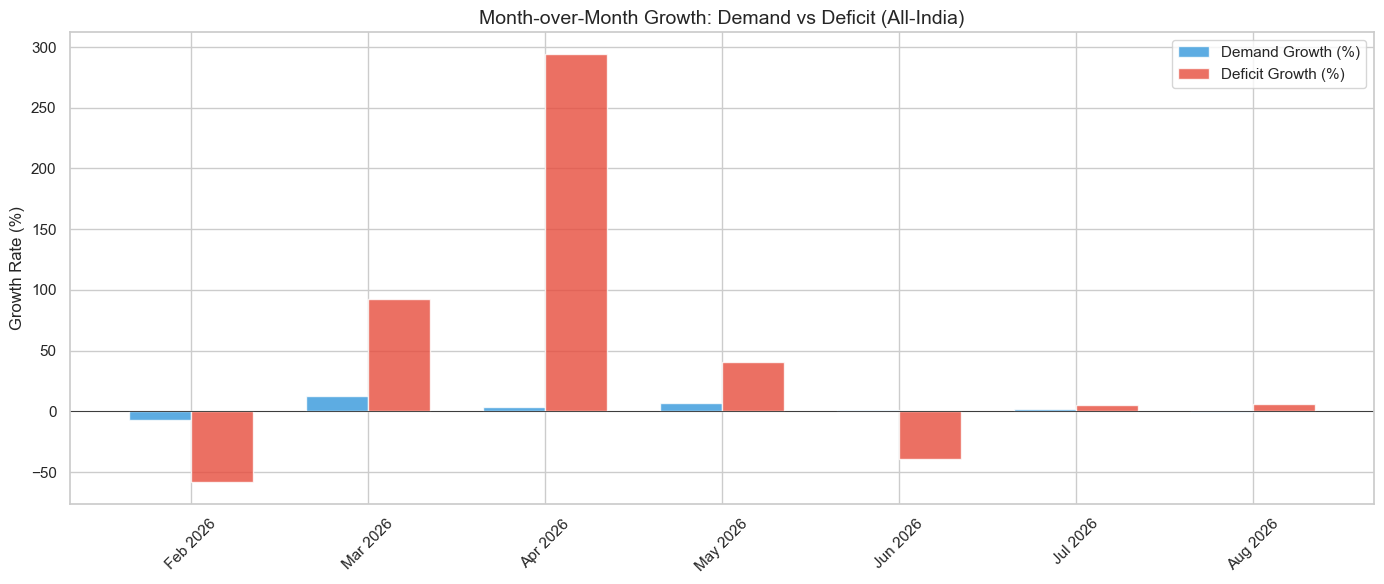

In [13]:
# Calculate MoM growth for All-India
df_ai = df_all_india.sort_values('month_start').copy()
df_ai['demand_growth_pct'] = df_ai['energy_requirement_mu'].pct_change() * 100
df_ai['deficit_growth_pct'] = df_ai['energy_not_supplied_mu'].pct_change() * 100

fig, ax = plt.subplots(figsize=(14, 6))
x = np.arange(len(df_ai.dropna()))
df_plot = df_ai.dropna(subset=['demand_growth_pct'])
width = 0.35

ax.bar(x - width/2, df_plot['demand_growth_pct'], width, label='Demand Growth (%)', color='#3498db', alpha=0.8)
ax.bar(x + width/2, df_plot['deficit_growth_pct'], width, label='Deficit Growth (%)', color='#e74c3c', alpha=0.8)
ax.set_xticks(x)
ax.set_xticklabels(df_plot['month_start'].dt.strftime('%b %Y'), rotation=45)
ax.set_title('Month-over-Month Growth: Demand vs Deficit (All-India)', fontsize=14)
ax.set_ylabel('Growth Rate (%)')
ax.legend()
ax.axhline(0, color='black', linewidth=0.5)
plt.tight_layout()
plt.show()

> **Finding:** If deficit growth outpaces demand growth in any month, it signals that grid capacity additions are lagging. This is a **critical time-series feature** for Member 3's forecasting model.

---
## Summary: Key EDA Findings & Handoffs

| # | Finding | Handoff To | Action |
|---|---------|------------|--------|
| 1 | National deficit gap is small but persistent | Member 3 | Use deficit growth *rate* as a feature |
| 2 | Northern & Western regions carry highest absolute stress | Member 4 | Regional bar chart on Overview dashboard |
| 3 | Summer months (Apr–Jul) drive peak demand | Member 3 | `month` confirmed as useful feature |
| 4 | `energy_requirement_mu` & `peak_demand_mw` are highly correlated | Member 3 | Drop one to avoid multicollinearity |
| 5 | `load_factor_pct` is independent of deficit metrics | Member 3 | Retain as clustering feature |
| 6 | NER has widest load factor spread | Member 3, 4 | Flag as volatile region |
| 7 | Vulnerability quadrant identifies 4 state profiles | Member 3, 4 | Use as flagship chart & clustering basis |
| 8 | Large states are statistical outliers in volume metrics | Member 3 | Use log-transform or robust scaling |
| 9 | Deficit growth rate vs demand growth rate reveals lag | Member 3 | Time-series forecasting feature |